In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [2]:
df = pd.read_csv(r"C:\Users\user\Downloads\archive (14)\Mall_Customers.csv")
print(df.shape)
print(df.head())
print(df.describe())
print("Missing values:", df.isnull().sum().sum())

(200, 5)
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40
       CustomerID         Age  Annual Income (k$)  Spending Score (1-100)
count  200.000000  200.000000          200.000000              200.000000
mean   100.500000   38.850000           60.560000               50.200000
std     57.879185   13.969007           26.264721               25.823522
min      1.000000   18.000000           15.000000                1.000000
25%     50.750000   28.750000           41.500000               34.750000
50%    100.500000   36.000000           61.500000               50.000000
75%    150.250000   49.000000           78.0000

In [3]:
features = ["Annual Income (k$)", "Spending Score (1-100)"]
X = df[features]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
k_values = range(2, 11)
inertias = []
silhouettes = []

for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    km.fit(X_scaled)
    inertias.append(km.inertia_)                     
    silhouettes.append(silhouette_score(X_scaled, km.labels_))
    print(f"k={k:2d}  inertia={km.inertia_:8.2f}  silhouette={silhouettes[-1]:.3f}")

C:\Users\user\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:110: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\user\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 199, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\user\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\user\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\user\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(

k= 2  inertia=  269.69  silhouette=0.321
k= 3  inertia=  157.70  silhouette=0.467
k= 4  inertia=  108.92  silhouette=0.494
k= 5  inertia=   65.57  silhouette=0.555
k= 6  inertia=   55.06  silhouette=0.540
k= 7  inertia=   44.86  silhouette=0.528
k= 8  inertia=   37.23  silhouette=0.455
k= 9  inertia=   32.39  silhouette=0.457
k=10  inertia=   29.98  silhouette=0.443


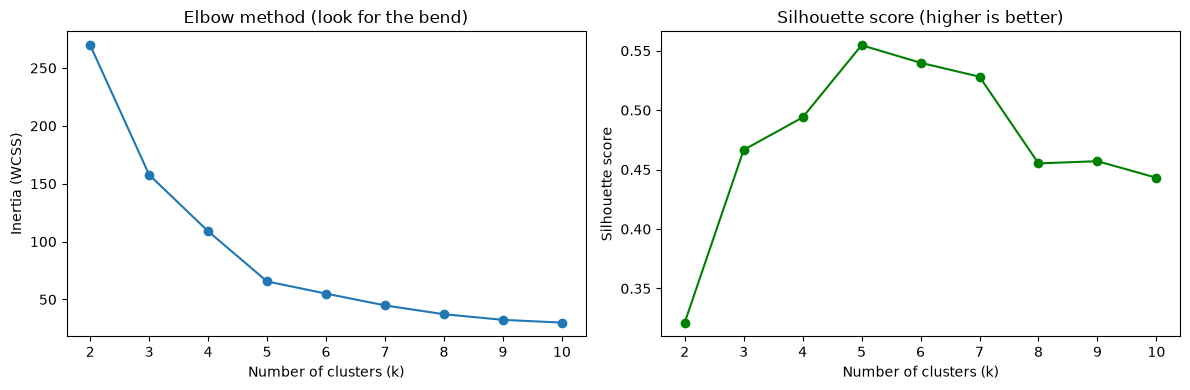

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(list(k_values), inertias, marker="o")
ax[0].set_xlabel("Number of clusters (k)")
ax[0].set_ylabel("Inertia (WCSS)")
ax[0].set_title("Elbow method (look for the bend)")

ax[1].plot(list(k_values), silhouettes, marker="o", color="green")
ax[1].set_xlabel("Number of clusters (k)")
ax[1].set_ylabel("Silhouette score")
ax[1].set_title("Silhouette score (higher is better)")
plt.tight_layout()

In [5]:
best_k = 5  # <- Choose from the elbow / silhouette plots
kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=42)
df["Cluster"] = kmeans.fit_predict(X_scaled)

print("\nCustomers per cluster:\n", df["Cluster"].value_counts().sort_index())
print("Final silhouette score:", round(silhouette_score(X_scaled, df["Cluster"]), 3))


Customers per cluster:
 Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64
Final silhouette score: 0.555


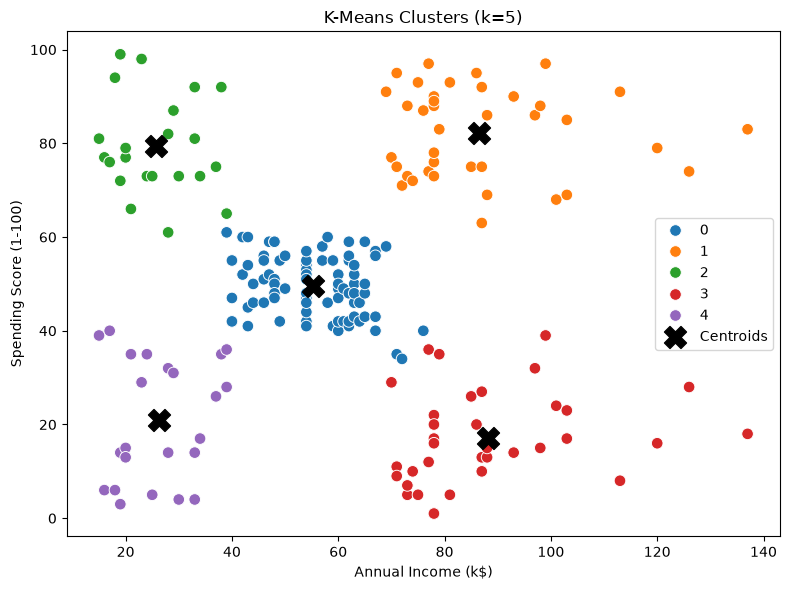

In [6]:
centroids = scaler.inverse_transform(kmeans.cluster_centers_)

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df, x=features[0], y=features[1],
    hue="Cluster", palette="tab10", s=70
)
plt.scatter(centroids[:, 0], centroids[:, 1],
            marker="X", s=250, c="black", label="Centroids")
plt.title(f"K-Means Clusters (k={best_k})")
plt.legend()
plt.tight_layout()
plt.show()